<a href="https://colab.research.google.com/github/dkundra374-sketch/Chest-X-ray-Pneumonia-Binary-Detection/blob/main/Chest_X_ray(Pneumonia).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [43]:
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/

cp: cannot stat 'kaggle.json': No such file or directory


In [44]:
!kaggle datasets download -d paultimothymooney/chest-xray-pneumonia

Dataset URL: https://www.kaggle.com/datasets/paultimothymooney/chest-xray-pneumonia
License(s): other
chest-xray-pneumonia.zip: Skipping, found more recently modified local copy (use --force to force download)


In [45]:
import zipfile
zip_ref = zipfile.ZipFile('/content/chest-xray-pneumonia.zip', 'r')
zip_ref.extractall('/content')
zip_ref.close()

In [46]:
import tensorflow as tf
from tensorflow import keras
from keras import Sequential
from keras.layers import Dense,Conv2D,MaxPooling2D,Flatten,BatchNormalization,Dropout,GlobalAveragePooling2D

In [47]:
#generators - divide whole data to batches.then one batch is load in ram at one time ,once it work is done it is removed and next batch comes to work
train_ds=keras.utils.image_dataset_from_directory(
    directory='/content/chest_xray/train',
    labels='inferred',
    label_mode='int',
    batch_size=32,
    image_size=(256,256),
    validation_split=0.2,
    subset='training',
    seed=42
)
validation_ds=keras.utils.image_dataset_from_directory(
    directory='/content/chest_xray/train',
    labels='inferred',
    label_mode='int',
    batch_size=32,
    image_size=(256,256),
    validation_split=0.2,
    subset='validation',
    seed=42
)
test_ds=keras.utils.image_dataset_from_directory(
    directory='/content/chest_xray/test',
    labels='inferred',
    label_mode='int',
    batch_size=32,
    image_size=(256,256),
    shuffle=False
)


Found 5216 files belonging to 2 classes.
Using 4173 files for training.
Found 5216 files belonging to 2 classes.
Using 1043 files for validation.
Found 624 files belonging to 2 classes.


In [48]:
#NORMALIZE: becaue stored 0-255 form we need it to convert it to 0-1
def process(image,label):
  image=tf.cast(image/255.0,tf.float32)
  return image,label

train_ds=train_ds.map(process).prefetch(tf.data.AUTOTUNE)       #added prefetch
validation_ds=validation_ds.map(process).prefetch(tf.data.AUTOTUNE)
test_ds=test_ds.map(process).prefetch(tf.data.AUTOTUNE)         # test set normalized

In [49]:
DROPOUT = 0.2
# create CNN model
model=Sequential()
model.add(tf.keras.layers.Input(shape=(256,256,3)))

model.add(Conv2D(64,kernel_size=(3,3),padding='same',activation='relu',input_shape=(256,256,3)))
model.add(BatchNormalization())
model.add(MaxPooling2D(pool_size=(2,2),padding='same'))


model.add(Conv2D(64,kernel_size=(3,3),padding='same',activation='relu'))
model.add(BatchNormalization())
model.add(MaxPooling2D(pool_size=(2,2),padding='same'))

model.add(Conv2D(128,kernel_size=(3,3),padding='same',activation='relu'))
model.add(BatchNormalization())
model.add(MaxPooling2D(pool_size=(2,2),padding='same'))


model.add(GlobalAveragePooling2D())   # CHANGED: was Flatten() (16.8M params -> far fewer, less overfitting)
#fully connected layer(3 layers)
model.add(Dense(256,activation='relu'))
model.add(Dropout(DROPOUT))
model.add(Dense(64,activation='relu'))
model.add(Dropout(DROPOUT))
model.add(Dense(1,activation='sigmoid'))#output


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [50]:
model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_9 (Conv2D)               │ (None, 256, 256, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_9           │ (None, 256, 256, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 128, 128, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 128, 128, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_10          │ (None, 128, 128, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 64, 64, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_11          │ (None, 64, 64, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_11 (MaxPooling2D) │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_3      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 256)            │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 64)             │        16,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 163,137 (637.25 KB)

 Trainable params: 162,625 (635.25 KB)

 Non-trainable params: 512 (2.00 KB)

In [51]:
#compile and execute
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=3e-4),   # CHANGED: lower learning rate (default 1e-3 was unstable)
    loss='binary_crossentropy',
    metrics=['accuracy',
             keras.metrics.Recall(name='recall'),
             keras.metrics.AUC(name='auc')]
)

In [52]:
class_weight = {0: 1.94, 1: 0.67}   # NORMAL is the minority class (1341 vs 3875)

callbacks = [                        # NEW
    keras.callbacks.EarlyStopping(monitor='val_loss', patience=6, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.3, patience=2, min_lr=1e-6),
]

history=model.fit(train_ds,
                  epochs=40,                        # CHANGED: 10 -> 40 (early stopping ends it sooner)
                  validation_data=validation_ds,
                  class_weight=class_weight,
                  callbacks=callbacks)

Epoch 1/40
131/131 ━━━━━━━━━━━━━━━━━━━━ 45s 281ms/step - accuracy: 0.8457 - auc: 0.9275 - loss: 0.3409 - recall: 0.8173 - val_accuracy: 0.7613 - val_auc: 0.6251 - val_loss: 0.7762 - val_recall: 1.0000 - learning_rate: 3.0000e-04
Epoch 2/40
131/131 ━━━━━━━━━━━━━━━━━━━━ 34s 260ms/step - accuracy: 0.8967 - auc: 0.9584 - loss: 0.2495 - recall: 0.8845 - val_accuracy: 0.7613 - val_auc: 0.4893 - val_loss: 1.9588 - val_recall: 1.0000 - learning_rate: 3.0000e-04
Epoch 3/40
131/131 ━━━━━━━━━━━━━━━━━━━━ 41s 259ms/step - accuracy: 0.9063 - auc: 0.9679 - loss: 0.2205 - recall: 0.8942 - val_accuracy: 0.7613 - val_auc: 0.4987 - val_loss: 2.3362 - val_recall: 1.0000 - learning_rate: 3.0000e-04
Epoch 4/40
131/131 ━━━━━━━━━━━━━━━━━━━━ 41s 257ms/step - accuracy: 0.9260 - auc: 0.9793 - loss: 0.1796 - recall: 0.9163 - val_accuracy: 0.7613 - val_auc: 0.4987 - val_loss: 2.4653 - val_recall: 1.0000 - learning_rate: 9.0000e-05
Epoch 5/40
131/131 ━━━━━━━━━━━━━━━━━━━━ 29s 223ms/step - accuracy: 0.9391 - auc: 0.9

In [53]:
model.evaluate(test_ds)

20/20 ━━━━━━━━━━━━━━━━━━━━ 4s 172ms/step - accuracy: 0.7131 - auc: 0.8825 - loss: 0.8271 - recall: 0.9872


[0.8271284699440002,
 0.7131410241127014,
 0.9871794581413269,
 0.8824511766433716]

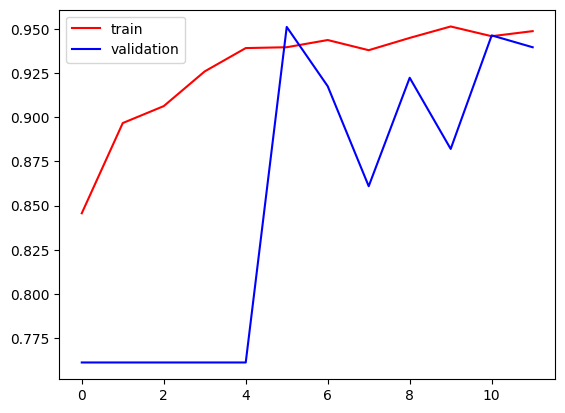

In [54]:
import matplotlib.pyplot as plt
plt.plot(history.history['accuracy'],color='red',label='train')
plt.plot(history.history['val_accuracy'],color='blue',label='validation')
plt.legend()
plt.show()

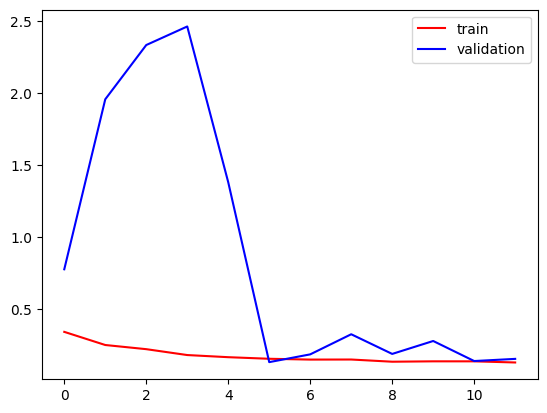

In [55]:
plt.plot(history.history['loss'],color='red',label='train')
plt.plot(history.history['val_loss'],color='blue',label='validation')
plt.legend()
plt.show()

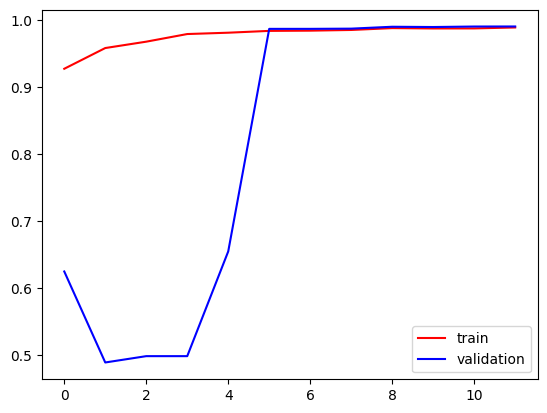

In [56]:
plt.plot(history.history['auc'],color='red',label='train')
plt.plot(history.history['val_auc'],color='blue',label='validation')
plt.legend()
plt.show()

In [57]:
#test with image:

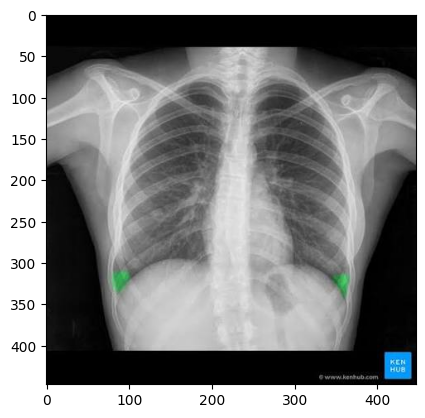

(447, 447, 3)
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 630ms/step
Prediction: NORMAL (90.8% confidence)


In [58]:
import cv2
import matplotlib.pyplot as plt

test_img = cv2.imread('/content/x-rayn.jpg')

test_img = cv2.cvtColor(test_img, cv2.COLOR_BGR2RGB)
plt.imshow(test_img)
plt.show()
print(test_img.shape)

test_img = cv2.resize(test_img, (256, 256))
test_input = test_img.reshape(1, 256, 256, 3) / 255.0

prediction = model.predict(test_input)
prob = prediction[0][0]
label = 'PNEUMONIA' if prob > 0.5 else 'NORMAL'
confidence = prob if prob > 0.5 else 1 - prob
print(f"Prediction: {label} ({confidence*100:.1f}% confidence)")